#### MPAS Kinetic Energy Spectrum (model-health check)
Regrids near-surface wind onto a regular lat/lon sub-grid and computes an isotropic KE spectrum vs. horizontal wavenumber via 2D FFT -- the standard mesoscale-model diagnostic (Skamarock 2004) for spotting spurious energy pile-up near the grid scale (under-damped noise) or an unexpectedly steep rolloff (over-diffusive run). Complements the domain-total KE time series in `mpas_conservation_check.ipynb`.

**Data**: SouthAmerica 240-48km variable-resolution tutorial run, one `history.*.nc` snapshot, lowest model level, over the ~48km-resolution nest.

Ming Ge Nov. 2026

In [1]:
import numpy as np
import xarray as xr
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

from mpas_utils import mpas_lonlat_deg

#### Load mesh and near-surface wind

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'

ds_i = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')
lonCell, latCell = mpas_lonlat_deg(ds_i['lonCell'].values, ds_i['latCell'].values)
points = np.column_stack([lonCell, latCell])

ds = xr.open_dataset(data_dir + 'history.2014-09-12_00.00.00.nc').squeeze()
u = ds['uReconstructZonal'].isel(nVertLevels=0).values
v = ds['uReconstructMeridional'].isel(nVertLevels=0).values

#### Regrid onto a regular lat/lon grid over the fine-mesh (~48km) nest

In [3]:
lon_bounds = (-80, -55)
lat_bounds = (-40, -15)
res_deg = 0.25  # a bit finer than the ~48km nest spacing (~0.43 deg)

glon = np.arange(lon_bounds[0], lon_bounds[1], res_deg)
glat = np.arange(lat_bounds[0], lat_bounds[1], res_deg)
LON, LAT = np.meshgrid(glon, glat)

Ug = griddata(points, u, (LON, LAT), method='linear')
Vg = griddata(points, v, (LON, LAT), method='linear')
Ug = np.nan_to_num(Ug, nan=np.nanmean(Ug))
Vg = np.nan_to_num(Vg, nan=np.nanmean(Vg))

#### 2D FFT -> isotropic KE spectrum

In [4]:
ny, nx = Ug.shape

# detrend (remove domain mean) and taper edges (Hann window) before the FFT, standard
# practice to limit spectral leakage from the non-periodic sub-domain boundary
window = np.outer(np.hanning(ny), np.hanning(nx))
Uw = (Ug - Ug.mean()) * window
Vw = (Vg - Vg.mean()) * window

Uf = np.fft.fftshift(np.fft.fft2(Uw))
Vf = np.fft.fftshift(np.fft.fft2(Vw))
psd2d = 0.5 * (np.abs(Uf) ** 2 + np.abs(Vf) ** 2)

# convert wavenumber from cycles/degree to cycles/km using a flat-earth approximation
# at the sub-domain's center latitude (fine for this narrow a latitude band)
lat0 = 0.5 * (lat_bounds[0] + lat_bounds[1])
km_per_deg_lon = 111.0 * np.cos(np.deg2rad(lat0))
km_per_deg_lat = 111.0

kx = np.fft.fftshift(np.fft.fftfreq(nx, d=res_deg * km_per_deg_lon))
ky = np.fft.fftshift(np.fft.fftfreq(ny, d=res_deg * km_per_deg_lat))
KX, KY = np.meshgrid(kx, ky)
K = np.sqrt(KX**2 + KY**2)  # cycles / km

kbins = np.linspace(0, K.max(), min(nx, ny) // 2)
k_centers = 0.5 * (kbins[1:] + kbins[:-1])
spectrum = np.array([
    psd2d[(K >= kbins[i]) & (K < kbins[i + 1])].mean()
    for i in range(len(k_centers))
])

#### Plot

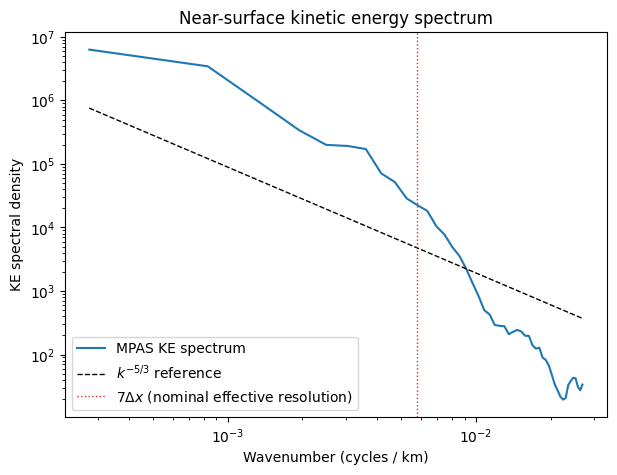

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(k_centers, spectrum, color='tab:blue', label='MPAS KE spectrum')

# -5/3 reference slope, anchored to the spectrum near the middle of the resolved range
# (searched outward from there in case that exact bin happened to be empty/NaN)
mid = len(k_centers) // 3
valid = np.where(np.isfinite(spectrum))[0]
ref_idx = valid[np.argmin(np.abs(valid - mid))]
ref = spectrum[ref_idx] * (k_centers / k_centers[ref_idx]) ** (-5 / 3)
ax.loglog(k_centers, ref, 'k--', lw=1, label=r'$k^{-5/3}$ reference')

dx_nominal = res_deg * km_per_deg_lon
ax.axvline(1 / (7 * dx_nominal), color='tab:red', ls=':', lw=1,
           label=r'$7\Delta x$ (nominal effective resolution)')

ax.set_xlabel('Wavenumber (cycles / km)')
ax.set_ylabel('KE spectral density')
ax.set_title('Near-surface kinetic energy spectrum')
ax.legend()

# Energy that flattens out or rises again near the grid scale (right edge) signals
# under-damped noise; a rolloff starting well before 7*dx signals excessive diffusion.
# Because this is a sub-box of a global mesh (not a periodic doubly-periodic domain),
# treat the slope as a qualitative health check rather than a precise spectral fit.